# Confidence limits and exclusion limits in HEP — a toy walkthrough

Condensed, runnable version of `README.md` in this directory (the README has the full
explanation, the source map into STAMET and the list of problems found in the sources).
Everything uses `cltoys.py`; the standalone scripts `01`–`05` do the same with more checks.

**Main sources**: book `confidenceIntervals.ipynb` c2 (Neyman), c5–c11 (Feldman–Cousins), c14 (CLs),
c16–c20 (profile likelihood, asymptotics, $q_\mu$); `2024/Lecture_9-2` p.5–46; `2024/Lecture_13-2`;
`2024/STAMET_May14_2024` p.2–43; `papers/1007.1727.pdf`; `papers/Feldman-Cousins…pdf`;
Combine docs `what_combine_does/statistical_tests.md` L173, `part3/commonstatsmethods.md` L7, L297.

In [1]:
%matplotlib inline
import numpy as np
from scipy import stats
import cltoys as ct
plt = ct.setup_style(agg=False)
C = ct.COLORS
rng = np.random.default_rng(2026)

## 1. A confidence interval is a procedure with guaranteed coverage

$[a(x), b(x)]$ is a $1-\alpha$ confidence interval if $P(a(x)\le\theta\le b(x)\mid\theta)\ge 1-\alpha$ **for every** $\theta$.
Neyman: for each $\theta$ pick an acceptance region of $x$ with probability $1-\alpha$ (build horizontally),
then the interval is the set of $\theta$ whose region contains $x_{obs}$ (read vertically).

For a Poisson count the exact construction gives
$\lambda_1=\tfrac12\chi^2_{\alpha/2}(2n)$, $\lambda_2=\tfrac12\chi^2_{1-\alpha/2}(2n+2)$; with $n=0$ the 95% upper limit is $-\ln 0.05 = 3.0$.
The toys below check the coverage directly: throw $n\sim\mathrm{Pois}(\lambda)$, build the interval, count how often it contains $\lambda$.

n=0 95% UL : 2.9957322735539895
n=9 90% CI : (np.float64(4.695227540344492), np.float64(15.705216422115459))


Text(0.5, 1.0, '68.3% Poisson intervals: exact sums (lines) and toys (markers)')

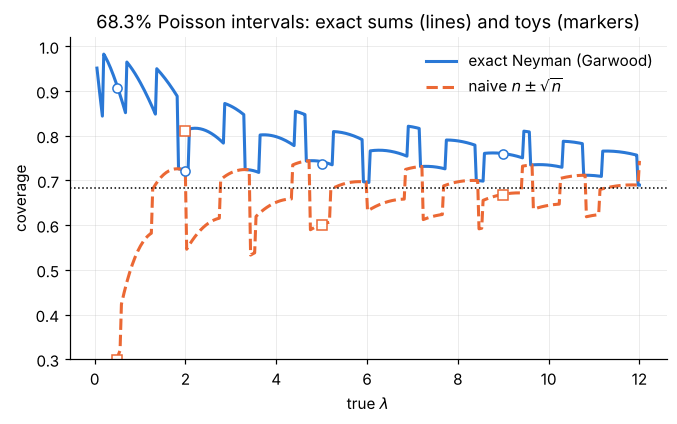

In [2]:
print("n=0 95% UL :", ct.poisson_interval(0, 0.95, "upper")[1])
print("n=9 90% CI :", ct.poisson_interval(9, 0.90, "central"))

lam_true = np.linspace(0.05, 12, 400)
garwood = lambda n: ct.poisson_interval(n, 0.6827, "central")
naive   = lambda n: (n - np.sqrt(n), n + np.sqrt(n))
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(lam_true, ct.poisson_exact_coverage(lam_true, garwood), color=C[0], label="exact Neyman (Garwood)")
ax.plot(lam_true, ct.poisson_exact_coverage(lam_true, naive), color=C[1], ls="--", label="naive $n\\pm\\sqrt{n}$")
for L in (0.5, 2.0, 5.0, 9.0):                      # toy check
    n = rng.poisson(L, 20000).astype(float)
    for f, c, m in ((garwood, C[0], "o"), (naive, C[1], "s")):
        lo, up = f(n); ax.plot(L, np.mean((lo <= L) & (L <= up)), m, color=c, mfc="white")
ax.axhline(0.6827, color="k", ls=":", lw=1); ax.set_ylim(0.3, 1.02)
ax.set_xlabel("true $\\lambda$"); ax.set_ylabel("coverage"); ax.legend(); ax.set_title("68.3% Poisson intervals: exact sums (lines) and toys (markers)")

## 2. Physical boundaries: flip-flop vs Feldman–Cousins

With $\mu\ge 0$, a deficit gives a negative or even empty classical interval. Choosing "upper limit or two-sided"
*after* looking at the data (flip-flop) breaks the coverage. Feldman–Cousins orders the acceptance region by
$R=L(x\mid\mu)/L(x\mid\mu_{best})$, $\mu_{best}=\max(0,\hat\mu)$, and covers by construction.

In [3]:
CL = 0.90
mu0 = 2.0                                         # flip-flop under-covers here
x = rng.normal(mu0, 1, 20000)
lo, up = ct.flipflop_interval(x, CL)
print(f"flip-flop coverage at mu = {mu0}: {np.mean((lo <= mu0) & (mu0 <= up)):.3f} (nominal {CL})")
belt = ct.fc_gaussian_belt(CL, mu_grid=np.linspace(0, 9, 901))
xs = np.linspace(-6, 10, 801)
tab = np.array([ct.fc_gaussian_interval(v, belt) for v in xs])
lo, up = np.interp(x, xs, tab[:, 0]), np.interp(x, xs, tab[:, 1])
print(f"Feldman-Cousins coverage at mu = {mu0}: {np.mean((lo <= mu0) & (mu0 <= up)):.3f}")

b = 3.0
pbelt = ct.fc_poisson_belt(b, CL)
print("\n n | classical 90% UL (b=3) | FC 90% interval")
for n in range(0, 8):
    ul = ct.poisson_interval(n, CL, "upper", b)[1]
    lo_fc, up_fc = ct.fc_poisson_interval(n, b, CL, belt=pbelt)
    print(f" {n} | {ul:7.2f} {'(negative!)' if ul < 0 else '':12s} | [{lo_fc:.2f}, {up_fc:.2f}]")

flip-flop coverage at mu = 2.0: 0.847 (nominal 0.9)


Feldman-Cousins coverage at mu = 2.0: 0.896



 n | classical 90% UL (b=3) | FC 90% interval
 0 |   -0.70 (negative!)  | [0.00, 0.95]
 1 |    0.89              | [0.00, 1.88]
 2 |    2.32              | [0.00, 3.04]
 3 |    3.68              | [0.00, 4.42]
 4 |    4.99              | [0.00, 5.59]
 5 |    6.27              | [0.00, 6.99]
 6 |    7.53              | [0.15, 8.46]
 7 |    8.77              | [0.90, 9.53]


## 3. Exclusion: CL$_{s+b}$ vs CLs

$CL_{s+b}=P(n\le n_{obs}\mid s+b)$, $CL_b=P(n\le n_{obs}\mid b)$, $CL_s=CL_{s+b}/CL_b$. Exclude $s$ at 95% if the quantity is $<0.05$.
$CL_{s+b}$ excludes *any* signal, however small, in 5% of background-only experiments. CLs does not, at the price of over-coverage.
For a Poisson count, CLs is numerically identical to the Bayesian limit with a flat prior on $s\ge0$.

In [4]:
b, CL = 3.0, 0.95
print(" n_obs  CL_s+b UL   CLs UL   Bayes(flat) UL")
for n in range(6):
    print(f" {n:4d}  {ct.counting_upper_limit(n, b, CL, 'CLsb'):8.3f}  {ct.counting_upper_limit(n, b, CL, 'CLs'):8.3f}"
          f"  {ct.counting_upper_limit(n, b, CL, 'bayes'):8.3f}")
n_b = rng.poisson(b, 50000)                      # background-only toys
for s in (0.1, 1.0, 4.0):
    print(f"P(exclude s={s} | b only):  CL_s+b {np.mean(ct.counting_upper_limit(n_b, b, CL, 'CLsb') < s):.3f}"
          f"   CLs {np.mean(ct.counting_upper_limit(n_b, b, CL, 'CLs') < s):.3f}")

 n_obs  CL_s+b UL   CLs UL   Bayes(flat) UL
    0    -0.004     2.996     2.996
    1     1.744     3.643     3.643
    2     3.296     4.443     4.443


    3     4.754     5.395     5.395
    4     6.154     6.480     6.480


    5     7.513     7.663     7.663
P(exclude s=0.1 | b only):  CL_s+b 0.050   CLs 0.000
P(exclude s=1.0 | b only):  CL_s+b 0.050   CLs 0.000
P(exclude s=4.0 | b only):  CL_s+b 0.425   CLs 0.201


## 4. The LHC recipe: $\tilde q_\mu$, frequentist toys, asymptotics

Binned spectrum, $E[n_i]=\mu s_i+b_i\kappa^\theta$, $\theta\sim N(a,1)$ (log-normal background normalisation, 10%).
For each tested $\mu$: $\tilde q_\mu$ on data; toys at $(\mu,\hat{\hat\theta}(\mu))$ and $(0,\hat{\hat\theta}(0))$ with the global
observable $a$ randomised; $p_\mu=P(\tilde q\ge\tilde q_{obs}\mid\mu)$, $1-p_b=P(\tilde q\ge\tilde q_{obs}\mid0)$, $CL_s=p_\mu/(1-p_b)$.
The asymptotic formulae (1007.1727) replace the toys by closed forms, with $\sigma$ taken from the Asimov data set.

mu = 1.180: toys CLs = 0.152 +- 0.007;  asymptotic CLs = 0.154


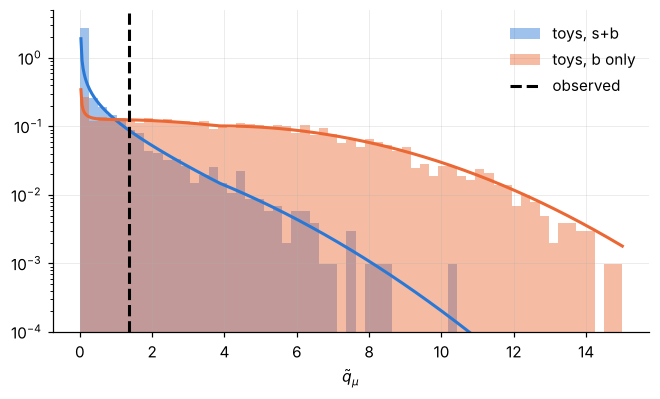

In [5]:
model, edges = ct.bump_model(125.0, s_tot=20, b_tot=1000, nuisance=("lnN", 1.10))
data_model, _ = ct.bump_model(150.0, s_tot=20, b_tot=1000, nuisance=("lnN", 1.10))
n_obs, a_obs = data_model.generate(1.5, 0.0, 1, np.random.default_rng(5))   # signal injected at 150 GeV

mu = ct.asymptotic_expected_limit(model, 0.95, 0)          # test mu near the expected limit
pt = ct.toy_cls_point(model, n_obs, a_obs, mu, 4000, rng)
sig = ct.sigma_asimov(model, mu)
print(f"mu = {mu:.3f}: toys CLs = {pt['CLs']:.3f} +- {pt['CLs_err']:.3f};  asymptotic CLs = {ct.asymptotic_cls(pt['q_obs'], mu, sig)[0]:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.8))
bins = np.linspace(0, 15, 60); w = np.full(4000, 1 / 4000 / (bins[1] - bins[0]))
ax.hist(pt["q_sb"], bins, weights=w, color=C[0], alpha=0.45, label="toys, s+b")
ax.hist(pt["q_b"], bins, weights=w, color=C[1], alpha=0.45, label="toys, b only")
qq = np.linspace(1e-3, 15, 500)
for mp, c in ((mu, C[0]), (0.0, C[1])):
    F = ct.qtilde_cdf_asym(qq, mu, mp, sig); ax.plot(qq[1:], np.diff(F) / np.diff(qq), color=c)
ax.axvline(pt["q_obs"], color="k", ls="--", label="observed")
ax.set_yscale("log"); ax.set_ylim(1e-4, 5); ax.set_xlabel("$\\tilde q_\\mu$"); ax.legend()

## 5. Expected limits and the Brazil plot

Expected limit = median upper limit under background only; the bands are its 16–84% and 2.5–97.5% quantiles.
Asymptotically $\mu_{up}^{\pm N}=\sigma_A[\Phi^{-1}(1-\alpha\Phi(N))\pm N]$ (1007.1727 eq. 89).

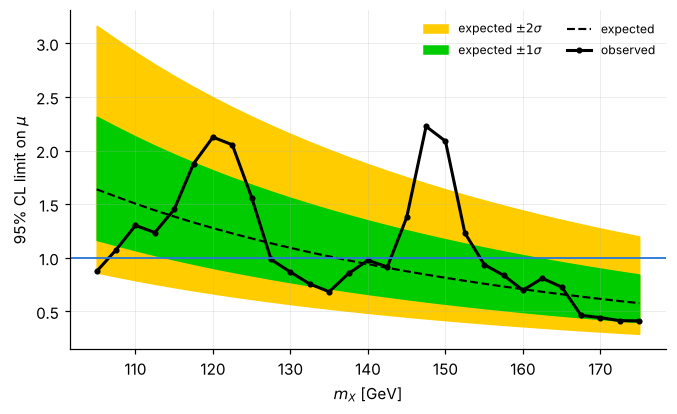

In [6]:
masses = np.arange(105.0, 175.1, 2.5)
rows = []
for m in masses:
    mm, _ = ct.bump_model(m, s_tot=20, b_tot=1000, nuisance=("lnN", 1.10))
    rows.append([ct.asymptotic_observed_limit(mm, n_obs, a_obs)] +
                [ct.asymptotic_expected_limit(mm, 0.95, k) for k in (-2, -1, 0, 1, 2)])
r = np.array(rows)
fig, ax = plt.subplots(figsize=(7, 4))
ax.fill_between(masses, r[:, 1], r[:, 5], color=ct.BRAZIL_2S, label="expected $\\pm2\\sigma$")
ax.fill_between(masses, r[:, 2], r[:, 4], color=ct.BRAZIL_1S, label="expected $\\pm1\\sigma$")
ax.plot(masses, r[:, 3], "k--", lw=1.4, label="expected")
ax.plot(masses, r[:, 0], "k-o", ms=3, label="observed")
ax.axhline(1, color=C[0], lw=1.2)
ax.set_xlabel("$m_X$ [GeV]"); ax.set_ylabel("95% CL limit on $\\mu$"); ax.legend(ncol=2, fontsize=8)

## 6. Things to try

- `ct.bump_model(..., b_tot=20, s_tot=5)`: low counts. The asymptotic and toy CLs separate (see also `03_cls_counting.py (d)`).
- Increase `kappa` (e.g. 1.5): the nuisance widens $f(\tilde q_\mu\mid\mu)$ and the limits worsen; the sidebands constrain it back.
- Replace `"qtilde"` by `"q"` in `ct.toy_cls_point(..., stat="q")` and look at what happens to the limit for a strong deficit ($\hat\mu<0$).
- Inject $\mu=0$ everywhere and repeat the Brazil plot 20 times: about 1 mass point in 20 should be outside the yellow band.